# Section 3 · Task 3.2 — Construct Parameterized Circuits

**Exam:** C1000-179 *Fundamentals of Quantum Computing Using Qiskit v2.X Developer*
**Section 3:** Create quantum circuits (≈ 18 % of the exam) → **Task 3.2: Construct parameterized circuits**
**Official references from the study guide:**
- [`qiskit.circuit.Parameter`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.Parameter)
- [`qiskit.circuit.QuantumCircuit`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit)
- [`qiskit.circuit.ParameterExpression`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.ParameterExpression)

Also relevant: [`ParameterVector`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.ParameterVector) · [Primitive input and output](https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output)

---

### IBM's self-test applied here
1. **How** do you put symbols into a circuit, combine them into expressions, and replace them with numbers (all at once, partly, by dictionary, by list, by vector)?
2. **Why** parameterize? (variational algorithms, parameter sweeps, building and **transpiling once** but running many times)
3. **What goes wrong if you do it incorrectly?** (two different `Parameter`s with the same name, values assigned in the wrong order, `bind_parameters` no longer exists, running a circuit that is still unbound, a Sampler PUB list that silently means *two* bindings …)

### What you will be able to do afterwards
- Create `Parameter`s and `ParameterVector`s, put them into gates, and read `qc.parameters` in the right order
- Build **`ParameterExpression`s** (`2*θ + φ/3 - 1`, `θ.sin()`, …) and evaluate, substitute and differentiate them
- Use **`assign_parameters`** in every form, with its options (`inplace`, `strict`, `flat_input`)
- Feed parameterized circuits to the **Sampler** and **Estimator** with parameter-value arrays and read the broadcast result shapes
- Write the **transpile-once, bind-many** pattern, and run a small variational optimisation loop
- Recognise Qiskit's parameterized **library** circuits (`n_local`, `real_amplitudes`, `efficient_su2`, `zz_feature_map`) and which old classes are deprecated

Exercise cells are stubs returning `None`, so the notebook runs end-to-end without your answers. **Solutions are at the end.**

In [1]:
import time, warnings
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import display
from scipy.optimize import minimize
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.circuit import Parameter, ParameterVector, ParameterExpression
from qiskit.circuit.exceptions import CircuitError
from qiskit.circuit.library import n_local, efficient_su2, real_amplitudes, zz_feature_map
from qiskit.primitives import StatevectorSampler, StatevectorEstimator
from qiskit.quantum_info import Statevector, SparsePauliOp
from qiskit.providers.fake_provider import GenericBackendV2

np.set_printoptions(precision=3, suppress=True)
print("qiskit", qiskit.__version__)

def _todo(name):
    print(f"⏳ {name}: not attempted yet — fill in the TODO above and re-run this cell.")

qiskit 2.6.1


---
## 1 · Why parameterized circuits?

A normal circuit has **numbers** in its gates: `qc.rx(0.7, 0)`. A **parameterized circuit** has **symbols** instead: `qc.rx(θ, 0)`. It is a *template* — you decide the numbers later.

Three situations where this is the right tool:

| Situation | What you do |
|---|---|
| **Variational algorithms** (VQE, QAOA, quantum ML) | an optimiser proposes new numbers each iteration; the *circuit structure* never changes |
| **Parameter sweeps** (plot an expectation value vs an angle) | one template, hundreds of numbers, one primitive call |
| **Efficiency on hardware** | **transpile the template once**, then only substitute numbers — transpilation is the slow step |

Rule of thumb for the exam: **a circuit with unbound parameters is a description, not something you can execute.**

---
## 2 · `Parameter`

```python
from qiskit.circuit import Parameter
theta = Parameter("θ")
```

- A `Parameter` is a **named symbol**. Any gate angle (`rx`, `ry`, `rz`, `p`, `u`, `cp`, `rzz`, …) and even a circuit's `global_phase` accepts one.
- The name is only a label. **Identity is by a hidden unique id (uuid), not by name.** Two `Parameter("a")` objects are **different** parameters — and Qiskit refuses to put both in one circuit.

In [2]:
theta, phi = Parameter("θ"), Parameter("φ")

qc = QuantumCircuit(2, 2)
qc.rx(theta, 0)
qc.ry(phi, 1)
qc.cx(0, 1)
qc.measure([0, 1], [0, 1])
print(qc)

print("\nqc.parameters     :", qc.parameters)
print("qc.num_parameters :", qc.num_parameters)
print("get_parameter('θ'):", qc.get_parameter("θ"), "| has_parameter('φ'):", qc.has_parameter("φ"))
print("gate.is_parameterized():", [inst.operation.is_parameterized() for inst in qc.data])

     ┌───────┐     ┌─┐   
q_0: ┤ Rx(θ) ├──■──┤M├───
     ├───────┤┌─┴─┐└╥┘┌─┐
q_1: ┤ Ry(φ) ├┤ X ├─╫─┤M├
     └───────┘└───┘ ║ └╥┘
c: 2/═══════════════╩══╩═
                    0  1 

qc.parameters     : ParameterView([Parameter(θ), Parameter(φ)])
qc.num_parameters : 2
get_parameter('θ'): θ | has_parameter('φ'): True
gate.is_parameterized(): [True, True, False, False, False]


### 2.1 Identity: same name ≠ same parameter

In [3]:
a1, a2 = Parameter("a"), Parameter("a")
print("a1 == a2 :", a1 == a2, "| same uuid:", a1.uuid == a2.uuid)

qc = QuantumCircuit(1)
qc.rx(a1, 0)
try:
    qc.ry(a2, 0)                       # a DIFFERENT parameter with the same name
except CircuitError as e:
    print("CircuitError:", e)

qc.ry(a1, 0)                           # re-using the SAME object is fine
print("same object used twice -> num_parameters =", qc.num_parameters)

a1 == a2 : False | same uuid: False
CircuitError: "name conflict adding parameter 'a'"
same object used twice -> num_parameters = 1


### 2.2 The order of `qc.parameters` — this matters for binding by list
`qc.parameters` is a sorted view. Parameters are sorted **alphabetically by name, case-sensitively** (upper-case letters before lower-case), *not* in the order you used them. Elements of a `ParameterVector` are sorted by **index**.

In [4]:
b, a, Z, c = Parameter("b"), Parameter("a"), Parameter("Z"), Parameter("c")
qc = QuantumCircuit(1)
for p in (b, a, Z, c):                  # used in the order b, a, Z, c
    qc.rx(p, 0)
print("used order      :", [p.name for p in (b, a, Z, c)])
print("qc.parameters   :", [p.name for p in qc.parameters], "  <- alphabetical, 'Z' < 'a' (ASCII)")

used order      : ['b', 'a', 'Z', 'c']
qc.parameters   : ['Z', 'a', 'b', 'c']   <- alphabetical, 'Z' < 'a' (ASCII)


### 2.3 What happens if you run an unbound circuit
Anything that needs numbers raises an error: `Statevector`, `Operator`, `gate.to_matrix()`, and primitives called without values.

In [5]:
qc = QuantumCircuit(1); qc.rx(theta, 0)
for label, f in [("Statevector(qc)", lambda: Statevector(qc)),
                 ("RX gate .to_matrix()", lambda: qc.data[0].operation.to_matrix()),
                 ("float(theta)", lambda: float(theta))]:
    try:
        f()
    except Exception as e:
        print(f"{label:<22} -> {type(e).__name__}: {str(e)[:70]}…")

Statevector(qc)        -> TypeError: Parameter expression with unbound parameters {Standalone { name: "θ", …
RX gate .to_matrix()   -> TypeError: Parameter expression with unbound parameters {Standalone { name: "θ", …
float(theta)           -> TypeError: Parameter expression with unbound parameters {Standalone { name: "θ", …


### 2.4 Parameters in `global_phase`
A circuit's global phase can also be symbolic:

In [6]:
g = QuantumCircuit(1)
g.global_phase = theta
print("parameters from global_phase:", g.parameters)
print("bound:", g.assign_parameters({theta: np.pi}).global_phase)

parameters from global_phase: ParameterView([Parameter(θ)])
bound: 3.141592653589793


---
## 3 · `ParameterExpression`

Combine parameters with arithmetic and the result is a **`ParameterExpression`** (a `Parameter` *is* one — the simplest kind). Expressions can go into any gate angle.

| Operation | Example |
|---|---|
| arithmetic | `2*θ + φ/3 - 1`, `θ**2`, `-θ`, `θ*φ` |
| functions (methods) | `θ.sin()`, `.cos()`, `.tan()`, `.arcsin()`, `.arccos()`, `.arctan()`, `.exp()`, `.log()`, `.abs()`, `.sign()`, `.conjugate()` |
| roots | no `.sqrt()` — use `θ**0.5` |
| inspect | `.parameters` (set of `Parameter`s inside), `.num_parameters`, `.is_real()` |
| evaluate | `.assign(p, value)` / `.bind({p: value})` / `.bind_all(...)`, `.numeric()`, `float(expr)` (only if fully bound) |
| symbolic | `.subs({p: other_expr})`, `.gradient(p)`, `.simplify()`, `.sympify()` |

In [7]:
expr = 2 * theta + phi / 3 - 1
print("expr            :", expr, "| type:", type(expr).__name__)
print("parameters      :", sorted(expr.parameters, key=lambda p: p.name))
print("sin / power     :", theta.sin(), "|", theta ** 2, "|", theta ** 0.5)

# evaluate
partial = expr.assign(theta, 0.5)                 # still depends on phi
print("\nassign θ=0.5    :", partial, "| num_parameters:", partial.num_parameters)
full = partial.assign(phi, 0.3)
print("assign φ=0.3    :", full, "| numeric():", full.numeric(), "| float:", float(full), "| is_real:", full.is_real())

# symbolic operations
print("\nsubs θ -> 2φ    :", expr.subs({theta: 2 * phi}))
print("d expr / dθ     :", expr.gradient(theta), "| d expr / dφ:", expr.gradient(phi))
print("sympy form      :", expr.sympify())
print("sin(θ) at π/2   :", float(theta.sin().assign(theta, np.pi / 2)))

expr            : 2*θ + φ/3 - 1 | type: ParameterExpression
parameters      : [Parameter(θ), Parameter(φ)]
sin / power     : sin(θ) | θ**2 | θ**0.5

assign θ=0.5    : 0 + φ/3 | num_parameters: 1
assign φ=0.3    : 0.09999999999999999 | numeric(): 0.09999999999999999 | float: 0.09999999999999999 | is_real: True

subs θ -> 2φ    : -1 + 4.333333333333333*φ
d expr / dθ     : 2 | d expr / dφ: 0.3333333333333333


sympy form      : 2*θ + φ/3 - 1
sin(θ) at π/2   : 1.0


> An expression stays **symbolic until every parameter in it is assigned**. `float(expr)` on an unbound expression raises `TypeError` (shown in §2.3).

### 3.1 Using expressions in a circuit
Several angles can depend on the **same** parameter — one number to change, many gates updated.

free parameters: ParameterView([Parameter(θ), Parameter(φ)])
 rx  angle = θ   (Parameter)
 ry  angle = 2*θ + φ/3 - 1   (ParameterExpression)
 rz  angle = 3.141592653589793*cos(θ)   (ParameterExpression)
 cp  angle = θ**2   (ParameterExpression)


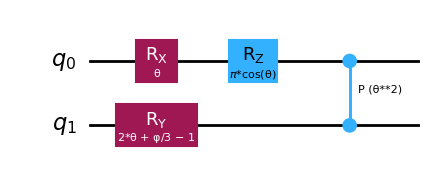

In [8]:
qc = QuantumCircuit(2)
qc.rx(theta, 0)
qc.ry(2 * theta + phi / 3 - 1, 1)       # an expression of two parameters
qc.rz(theta.cos() * np.pi, 0)           # a function of one
qc.cp(theta ** 2, 0, 1)
print("free parameters:", qc.parameters)
for inst in qc.data:
    print(f"{inst.operation.name:>3}  angle = {inst.operation.params[0]}   ({type(inst.operation.params[0]).__name__})")
qc.draw("mpl")

---
## 4 · `ParameterVector` — many parameters at once

```python
v = ParameterVector("v", 4)      # v[0], v[1], v[2], v[3]
```

- Behaves like a list: `len(v)`, `v[i]`, slicing, iteration.
- Elements are `ParameterVectorElement`s (a kind of `Parameter`) named **`v[0]`, `v[1]`, …** with `.vector` and `.index` attributes.
- **Sorted by numeric index** in `qc.parameters` (so `v[2]` comes before `v[10]`, unlike a plain name sort).
- Resizable with `v.resize(n)` before use.
- The standard way to build **ansätze** with layers of rotations.

v, ['v[0]', 'v[1]', 'v[2]', 'v[3]'] | len: 4 | v[1]: v[1] | name of element: v[1]
element info    : ParameterVectorElement | .vector.name = v | .index = 1

parameters: ['v[0]', 'v[1]', 'v[2]', 'v[3]']


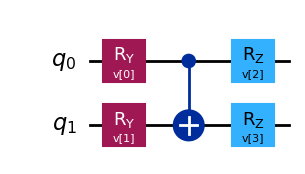

In [9]:
v = ParameterVector("v", 4)
print(v, "| len:", len(v), "| v[1]:", v[1], "| name of element:", v[1].name)
print("element info    :", type(v[1]).__name__, "| .vector.name =", v[1].vector.name, "| .index =", v[1].index)

# a small ansatz: RY layer, entangle, RZ layer
ans = QuantumCircuit(2)
for i in range(2):
    ans.ry(v[i], i)
ans.cx(0, 1)
for i in range(2):
    ans.rz(v[2 + i], i)
print("\nparameters:", [p.name for p in ans.parameters])
ans.draw("mpl")

In [10]:
# numeric ordering for longer vectors: w[2] sorts before w[10]
w = ParameterVector("w", 12)
c = QuantumCircuit(1)
for p in w:
    c.rx(p, 0)
print([p.name for p in c.parameters])

# mixing plain parameters and vectors: sorted by NAME ('a[...]' < 'x')
pp = QuantumCircuit(1)
x1 = Parameter("x"); av = ParameterVector("a", 2)
pp.rx(x1, 0); pp.ry(av[1], 0); pp.rz(av[0], 0)
print("mixed ordering:", [p.name for p in pp.parameters])

['w[0]', 'w[1]', 'w[2]', 'w[3]', 'w[4]', 'w[5]', 'w[6]', 'w[7]', 'w[8]', 'w[9]', 'w[10]', 'w[11]']
mixed ordering: ['a[0]', 'a[1]', 'x']


---
## 5 · Binding: `assign_parameters`

```python
bound = qc.assign_parameters(parameters, inplace=False, *, flat_input=False, strict=True)
```

| Argument | Meaning |
|---|---|
| `parameters` | a **dict** `{Parameter: value}` **or** a **sequence** of values (matched to `qc.parameters` order) |
| `inplace` | `False` (default) → return a **new** circuit; `True` → modify `qc` and **return `None`** |
| `strict` | `True` (default) → error if you pass a parameter the circuit does not have; `False` → ignore it |
| `flat_input` | allow dictionary keys that are `ParameterVector`s with flattened value lists |

A **value** can be a number, **another `Parameter`**, or a **`ParameterExpression`** — so you can rename parameters or tie one to another.

> **`bind_parameters` was removed in Qiskit 2.0.** Use `assign_parameters`.

In [11]:
print("has bind_parameters  :", hasattr(QuantumCircuit(1), "bind_parameters"))
print("has assign_parameters:", hasattr(QuantumCircuit(1), "assign_parameters"))

has bind_parameters  : False
has assign_parameters: True


### 5.1 By dictionary — and the original is untouched

In [12]:
qc = QuantumCircuit(2)
qc.rx(theta, 0)
qc.ry(2 * theta + phi, 1)
qc.cx(0, 1)

bound = qc.assign_parameters({theta: 0.5, phi: 0.25})
print("bound.parameters    :", bound.parameters, "| bound.num_parameters:", bound.num_parameters)
print("angles in bound     :", [inst.operation.params[0] for inst in bound.data[:2]], " <- plain floats now")
print("original unchanged  :", qc.num_parameters, "parameters")
print("now it is executable:", {str(k): round(float(v), 3) for k, v in Statevector(bound).probabilities_dict().items()})

bound.parameters    : ParameterView([]) | bound.num_parameters: 0
angles in bound     : [0.5, 1.25]  <- plain floats now
original unchanged  : 2 parameters
now it is executable: {'00': 0.617, '01': 0.021, '10': 0.321, '11': 0.04}


### 5.2 Partial binding
Binding only some parameters gives a *less* parameterized circuit — useful to fix some angles (e.g. a trained layer) and keep others free.

In [13]:
part = qc.assign_parameters({theta: 0.5})
print("remaining free parameters:", part.parameters)
print("second gate angle is now the expression:", part.data[1].operation.params[0])
final = part.assign_parameters({phi: 0.25})
print("fully bound after second call:", final.num_parameters == 0)

remaining free parameters: ParameterView([Parameter(φ)])
second gate angle is now the expression: 1 + φ
fully bound after second call: True


### 5.3 By sequence — values follow `qc.parameters` order
This is the easiest place to make a mistake: the list is matched to the **sorted** parameter order (§2.2), *not* the order you wrote the gates.

In [14]:
qc2 = QuantumCircuit(1)
beta, alpha = Parameter("beta"), Parameter("alpha")
qc2.rx(beta, 0)            # used first
qc2.ry(alpha, 0)           # used second
print("qc2.parameters order:", [p.name for p in qc2.parameters])

by_list = qc2.assign_parameters([10.0, 20.0])          # 10 -> alpha, 20 -> beta  (alphabetical!)
print("angles after list [10, 20] (rx, ry):", [float(i.operation.params[0]) for i in by_list.data])
by_dict = qc2.assign_parameters({beta: 10.0, alpha: 20.0})
print("angles after dict beta=10, alpha=20:", [float(i.operation.params[0]) for i in by_dict.data])

qc2.parameters order: ['alpha', 'beta']
angles after list [10, 20] (rx, ry): [20.0, 10.0]
angles after dict beta=10, alpha=20: [10.0, 20.0]


**Dictionaries are safer than lists** — they do not depend on the sort order. Dictionary keys may also be the parameter **names** (strings).

In [15]:
print("string key works:", qc.assign_parameters({"θ": 0.5}).parameters)

string key works: ParameterView([Parameter(φ)])


### 5.4 By vector
For a `ParameterVector`, pass the vector as a key and a list as the value.

In [16]:
bound_vec = ans.assign_parameters({v: [0.1, 0.2, 0.3, 0.4]})
print("angles:", [round(float(i.operation.params[0]), 2) for i in bound_vec.data if i.operation.params])
# or a flat list in qc.parameters order:
print("same via list:", [round(float(i.operation.params[0]), 2) for i in ans.assign_parameters([0.1, 0.2, 0.3, 0.4]).data if i.operation.params])

angles: [0.1, 0.2, 0.3, 0.4]
same via list: [0.1, 0.2, 0.3, 0.4]


### 5.5 Parameter → parameter (renaming) and parameter → expression

In [17]:
renamed = qc.assign_parameters({theta: phi})            # θ replaced by φ: one parameter left
print("θ -> φ                  :", renamed.parameters)
tied = qc.assign_parameters({theta: 2 * phi})           # θ replaced by 2φ
print("θ -> 2φ                 :", tied.parameters, "| first angle:", tied.data[0].operation.params[0])

θ -> φ                  : ParameterView([Parameter(φ)])
θ -> 2φ                 : ParameterView([Parameter(φ)]) | first angle: 2*φ


### 5.6 `inplace` and `strict`

In [18]:
c1 = qc.copy()
ret = c1.assign_parameters({theta: 0.5, phi: 0.25}, inplace=True)
print("inplace=True returns :", ret, "| c1 is now bound:", c1.num_parameters == 0)

stranger = Parameter("not_in_circuit")
try:
    qc.assign_parameters({stranger: 1.0})                          # strict=True (default)
except CircuitError as e:
    print("\nstrict=True  ->", type(e).__name__, ":", e)
print("strict=False ->", qc.assign_parameters({stranger: 1.0}, strict=False).num_parameters, "parameters still free (nothing was bound)")

inplace=True returns : None | c1 is now bound: True

strict=True  -> CircuitError : 'Cannot bind parameters (not_in_circuit) not present in the circuit.'
strict=False -> 2 parameters still free (nothing was bound)


---
## 6 · Running parameterized circuits with the primitives

You **do not** have to call `assign_parameters` yourself: put the template and a **parameter-value array** into a **PUB** and the primitive binds for you — for *many* value sets at once.

| Primitive | PUB tuple | Result |
|---|---|---|
| `Sampler` | `(circuit, parameter_values, shots)` | `result[0].data.<creg>` — a `BitArray` whose **shape** = broadcast shape |
| `Estimator` | `(circuit, observables, parameter_values, precision)` | `result[0].data.evs` (expectation values) and `.stds` |

**Parameter values** form an array of shape `(…, n_params)`: the **last axis** lists the values for `qc.parameters` (in that order); every leading axis is a *sweep dimension*. A dict `{param: array_of_values}` works too.

### 6.1 Sampler sweep
$R_Y(\theta)|0\rangle$ gives $P(1)=\sin^2(\theta/2)$. We sweep 21 angles in **one** call.

BitArray shape (the sweep shape): (21,)


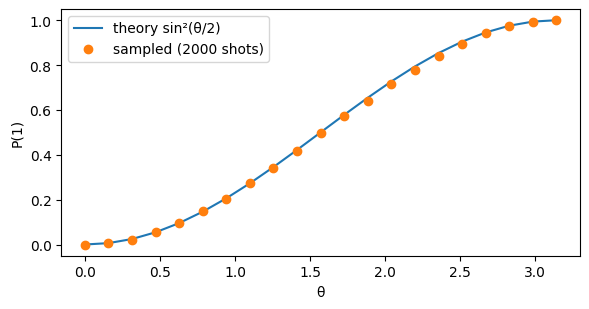

In [19]:
sweep = QuantumCircuit(1, 1)
sweep.ry(theta, 0)
sweep.measure(0, 0)

thetas = np.linspace(0, np.pi, 21).reshape(-1, 1)          # shape (21, 1): 21 sets of 1 parameter
shots = 2000
res = StatevectorSampler(seed=3).run([(sweep, thetas, shots)]).result()[0]
print("BitArray shape (the sweep shape):", res.data.c.shape)

p1 = np.array([res.data.c.get_counts(i).get("1", 0) / shots for i in range(21)])
x = thetas[:, 0]
plt.figure(figsize=(6, 3.2))
plt.plot(x, np.sin(x / 2) ** 2, label="theory sin²(θ/2)")
plt.plot(x, p1, "o", label=f"sampled ({shots} shots)")
plt.xlabel("θ"); plt.ylabel("P(1)"); plt.legend(); plt.tight_layout(); plt.show()

In [20]:
# Equivalent dict form: {parameter: array of values}
res_d = StatevectorSampler(seed=3).run([(sweep, {theta: x}, shots)]).result()[0]
print("dict form shape:", res_d.data.c.shape)

# A 2-D sweep: shape (3, 4, 1) -> result shape (3, 4)
grid = np.linspace(0, np.pi, 12).reshape(3, 4, 1)
print("grid sweep shape:", StatevectorSampler(seed=1).run([(sweep, grid, 100)]).result()[0].data.c.shape)

dict form shape: (21,)
grid sweep shape: (3, 4)


### 6.2 Shape traps (what happens if you do it incorrectly)

In [21]:
sampler = StatevectorSampler(seed=1)

# (1) forgetting the values
try:
    sampler.run([sweep], shots=10).result()
except ValueError as e:
    print("(1) no values      ->", type(e).__name__, ":", str(e)[:75], "…")

# (2) a flat list is read as a SWEEP, not as one parameter set
one_param = sampler.run([(sweep, [0.1, 0.2], 10)]).result()[0].data.c.shape
print("(2) values [0.1, 0.2] for a 1-parameter circuit -> shape", one_param, " = TWO bindings (θ=0.1 and θ=0.2), not an error!")

# (3) the right way to give ONE binding: a list of length n_params
print("(3) values [0.1]       -> shape", sampler.run([(sweep, [0.1], 10)]).result()[0].data.c.shape, "(a single binding)")

(1) no values      -> ValueError : The number of values (0) does not match the number of parameters (1) for th …
(2) values [0.1, 0.2] for a 1-parameter circuit -> shape (2,)  = TWO bindings (θ=0.1 and θ=0.2), not an error!
(3) values [0.1]       -> shape () (a single binding)


### 6.3 Estimator, observables and broadcasting
The Estimator **broadcasts** the observable array against the parameter-sweep shape (NumPy rules). For $|\psi(\theta)\rangle=\text{CX}\,R_Y(\theta)|00\rangle=\cos\frac\theta2|00\rangle+\sin\frac\theta2|11\rangle$:

$$\langle ZZ\rangle=1,\qquad \langle XX\rangle=\sin\theta,\qquad \langle ZI\rangle=\cos\theta .$$

To get **every observable at every angle** shape the observables `(3, 1)` and the values `(5, 1)` → the sweep shape is `(5,)` → result shape `(3, 5)`.

result shape: (3, 5) (3 observables x 5 angles)
[[ 1.     1.     1.     1.     1.   ]
 [ 0.     0.707  1.     0.707  0.   ]
 [ 1.     0.707  0.    -0.707 -1.   ]]


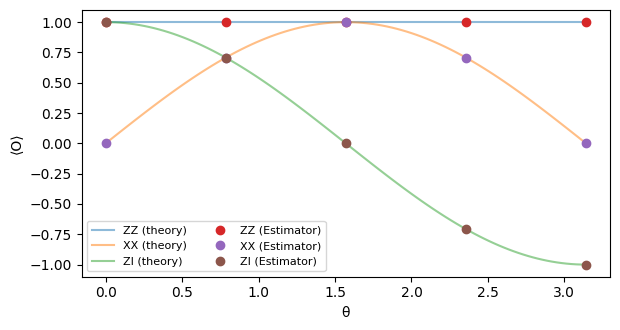

In [22]:
ec = QuantumCircuit(2)
ec.ry(theta, 0)
ec.cx(0, 1)                                   # NO measurements: the Estimator works on the state

observables = [SparsePauliOp("ZZ"), SparsePauliOp("XX"), SparsePauliOp("ZI")]
angles = np.linspace(0, np.pi, 5).reshape(-1, 1)        # 5 parameter sets

est = StatevectorEstimator()
evs = est.run([(ec, [[o] for o in observables], angles)]).result()[0].data.evs
print("result shape:", evs.shape, "(3 observables x 5 angles)")
print(evs.round(3))

fine = np.linspace(0, np.pi, 100)
plt.figure(figsize=(6.3, 3.4))
for name, curve in [("ZZ", np.ones_like(fine)), ("XX", np.sin(fine)), ("ZI", np.cos(fine))]:
    plt.plot(fine, curve, alpha=0.5, label=f"{name} (theory)")
for row, name in zip(evs, ["ZZ", "XX", "ZI"]):
    plt.plot(angles[:, 0], row, "o", label=f"{name} (Estimator)")
plt.xlabel("θ"); plt.ylabel("⟨O⟩"); plt.legend(ncol=2, fontsize=8); plt.tight_layout(); plt.show()

In [23]:
# One parameter set + a list of observables -> one value per observable
print("3 observables, one binding   :", est.run([(ec, observables, [0.5])]).result()[0].data.evs.round(3), " shape (3,)")
# One observable + a sweep            -> one value per binding
print("1 observable, 5 bindings     :", est.run([(ec, SparsePauliOp('XX'), angles)]).result()[0].data.evs.round(3), " shape (5,)")
# Incompatible shapes raise an error: observables (3,) vs sweep (5,)
try:
    est.run([(ec, observables, angles)])
except ValueError as e:
    print("observables (3,) vs sweep (5,) ->", type(e).__name__, ":", str(e)[:70], "…")

3 observables, one binding   : [1.    0.479 0.878]  shape (3,)


1 observable, 5 bindings     : [0.    0.707 1.    0.707 0.   ]  shape (5,)
observables (3,) vs sweep (5,) -> ValueError : The observables shape (3,) and the parameter values shape (5,) are not …


> The same PUB format works unchanged with Aer's `SamplerV2`/`EstimatorV2` and with IBM Runtime primitives. That is the point of the primitive interface — see Sections 4–6 of the exam.

In [24]:
# Proof: the very same PUBs run unchanged on Aer's primitives
from qiskit_aer.primitives import SamplerV2 as AerSampler, EstimatorV2 as AerEstimator
r = AerSampler(seed=1).run([(sweep, thetas[:5], 500)]).result()[0]
print("Aer SamplerV2   : sweep shape", r.data.c.shape, "| P(1) at the 5 angles:", [round(r.data.c.get_counts(i).get('1', 0) / 500, 2) for i in range(5)])
e = AerEstimator().run([(ec, SparsePauliOp("XX"), angles)]).result()[0].data.evs
print("Aer EstimatorV2 : <XX> at the 5 angles:", np.round(e, 2), "  (theory sin θ:", np.round(np.sin(angles[:, 0]), 2), ")")

Aer SamplerV2   : sweep shape (5,) | P(1) at the 5 angles: [0.0, 0.01, 0.03, 0.03, 0.1]
Aer EstimatorV2 : <XX> at the 5 angles: [0.   0.71 1.   0.71 0.  ]   (theory sin θ: [0.   0.71 1.   0.71 0.  ] )


### 6.4 Why `qc.parameters` order matters here too
For a PUB the **last axis of the value array follows `qc.parameters` order** (the same sorted order as §2.2). A dict `{param: values}` avoids any doubt.

---
## 7 · Transpile once, bind many times

Transpilation (layout, routing, gate translation) is the **expensive** step. A parameterized circuit **stays parameterized through transpilation** — angle expressions are carried along — so you can transpile the *template* once and then only substitute numbers.

In [25]:
backend = GenericBackendV2(num_qubits=7, coupling_map=[[0,1],[1,0],[1,2],[2,1],[1,3],[3,1],[3,5],[5,3],[4,5],[5,4],[5,6],[6,5]], seed=2)

template = efficient_su2(4, reps=2)                       # a parameterized ansatz from the library (§8)
rng = np.random.default_rng(0)
value_sets = rng.uniform(0, 2 * np.pi, size=(15, template.num_parameters))

# (A) naive: bind first, transpile every time
t0 = time.perf_counter()
for vals in value_sets:
    transpile(template.assign_parameters(vals), backend, optimization_level=1, seed_transpiler=1)
t_naive = time.perf_counter() - t0

# (B) smart: transpile the template once, then bind
t0 = time.perf_counter()
isa = transpile(template, backend, optimization_level=1, seed_transpiler=1)
bound = [isa.assign_parameters(vals) for vals in value_sets]
t_smart = time.perf_counter() - t0

print("template parameters:", template.num_parameters, "| transpiled template keeps them:", isa.num_parameters == template.num_parameters)
print(f"naive (transpile {len(value_sets)}x): {t_naive:.3f} s")
print(f"smart (transpile 1x + bind):  {t_smart:.3f} s   ->  about {t_naive / t_smart:.0f}x faster")
print("all bound circuits are fully numeric:", all(b.num_parameters == 0 for b in bound))

template parameters: 24 | transpiled template keeps them: True
naive (transpile 15x): 0.106 s
smart (transpile 1x + bind):  0.004 s   ->  about 30x faster
all bound circuits are fully numeric: True


(Exact timings vary by machine; the *ratio* is what matters. On a real backend the saving is larger because the `Estimator`/`Sampler` can also take the **template + value array** in a single PUB, so even the binding happens server-side.)

---
## 8 · Parameterized circuits from the library

`qiskit.circuit.library` ships ready-made **parameterized** circuits. In Qiskit 2.x they are **functions that return an ordinary `QuantumCircuit`** carrying a `ParameterVector`:

| Function | Typical use | Parameters |
|---|---|---|
| `n_local(num_qubits, rotation_blocks, entanglement_blocks, entanglement, reps, …)` | general layered ansatz | `θ[0…]` |
| `real_amplitudes(n, reps=…)` | RY layers + CX entanglement → real amplitudes | `θ[…]` |
| `efficient_su2(n, reps=…)` | RY+RZ layers + CX entanglement | `θ[…]` |
| `zz_feature_map(n, reps=…)` / `pauli_feature_map` | **data encoding** for quantum ML | `x[…]` |
| `qaoa_ansatz`, `evolved_operator_ansatz`, `hamiltonian_variational_ansatz` | problem-inspired | `β`, `γ`, … |

The **older classes** `TwoLocal`, `RealAmplitudes`, `EfficientSU2`, `NLocal`, `ZZFeatureMap`, `PauliFeatureMap`, `QAOAAnsatz` are **deprecated** in the 2.x series — prefer the functions.

n_local(3, ['ry'], 'cz', reps=2)     type=QuantumCircuit qubits=3  params= 9  first: ['θ[0]', 'θ[1]', 'θ[2]']
real_amplitudes(3, reps=2)           type=QuantumCircuit qubits=3  params= 9  first: ['θ[0]', 'θ[1]', 'θ[2]']
efficient_su2(3, reps=1)             type=QuantumCircuit qubits=3  params=12  first: ['θ[0]', 'θ[1]', 'θ[2]']
zz_feature_map(2, reps=1)            type=QuantumCircuit qubits=2  params= 2  first: ['x[0]', 'x[1]']

real_amplitudes: (reps+1) * n_qubits = 9 parameters


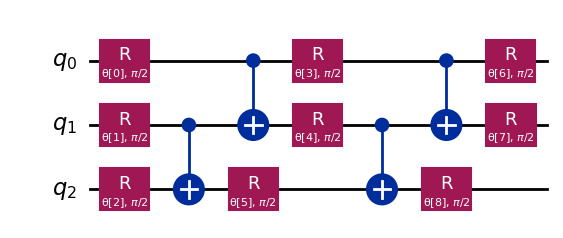

In [26]:
for name, circ in [("n_local(3, ['ry'], 'cz', reps=2)", n_local(3, ["ry"], "cz", reps=2)),
                   ("real_amplitudes(3, reps=2)", real_amplitudes(3, reps=2)),
                   ("efficient_su2(3, reps=1)", efficient_su2(3, reps=1)),
                   ("zz_feature_map(2, reps=1)", zz_feature_map(2, reps=1))]:
    print(f"{name:<36} type={type(circ).__name__:<14} qubits={circ.num_qubits}  params={circ.num_parameters:>2}  first: {[p.name for p in circ.parameters][:3]}")

ra = real_amplitudes(3, reps=2)
print("\nreal_amplitudes: (reps+1) * n_qubits =", 3 * 3, "parameters")
ra.decompose().draw("mpl", fold=-1)

In [27]:
# Deprecation made visible
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    from qiskit.circuit.library import TwoLocal
    _ = TwoLocal(2, "ry", "cx")
print("TwoLocal(...) ->", str(caught[0].message)[:150], "…")

TwoLocal(...) -> The class ``qiskit.circuit.library.n_local.two_local.TwoLocal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qis …


Library ansätze are **bound exactly like your own circuits**:

In [28]:
ra_bound = ra.assign_parameters(rng.uniform(0, np.pi, ra.num_parameters))
print("fully bound:", ra_bound.num_parameters == 0)
print("|amplitudes| of the 3-qubit state:", np.abs(Statevector(ra_bound).data).round(3))
print("real_amplitudes gives REAL amplitudes (zero imaginary part):", np.allclose(Statevector(ra_bound).data.imag, 0))

fully bound: True
|amplitudes| of the 3-qubit state: [0.3   0.112 0.533 0.325 0.33  0.158 0.511 0.336]
real_amplitudes gives REAL amplitudes (zero imaginary part): True


---
## 9 · A first variational loop (the reason parameterized circuits exist)

Find the ground-state energy of $H=Z+\tfrac12X$ with a one-parameter ansatz $R_Y(\theta)|0\rangle$:

$$E(\theta)=\langle Z\rangle+\tfrac12\langle X\rangle=\cos\theta+\tfrac12\sin\theta,\qquad E_{\min}=-\sqrt{1+\tfrac14}=-1.118\ldots$$

The optimiser only ever changes the **numbers**; the circuit is built once.

optimal θ = 3.6052  (theory: π + arctan(1/2) = 3.6052)
energy    = -1.118034   exact ground energy = -1.118034   |error| = 0.00e+00
evaluations: 45


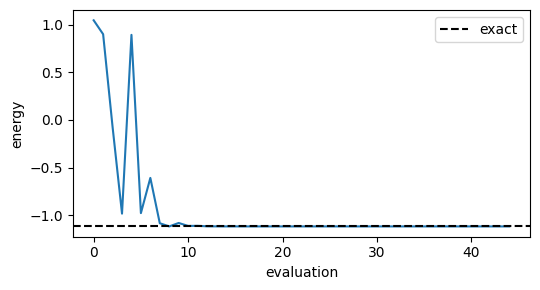

In [29]:
ansatz = QuantumCircuit(1)
ansatz.ry(theta, 0)
H = SparsePauliOp.from_list([("Z", 1.0), ("X", 0.5)])
estimator = StatevectorEstimator()

history = []
def energy(x):
    e = float(estimator.run([(ansatz, H, [x[0]])]).result()[0].data.evs)
    history.append(e)
    return e

opt = minimize(energy, x0=[0.1], method="COBYLA", tol=1e-8)
exact = np.linalg.eigvalsh(H.to_matrix()).min()
print(f"optimal θ = {opt.x[0]:.4f}  (theory: π + arctan(1/2) = {np.pi + np.arctan(0.5):.4f})")
print(f"energy    = {opt.fun:.6f}   exact ground energy = {exact:.6f}   |error| = {abs(opt.fun - exact):.2e}")
print("evaluations:", len(history))
plt.figure(figsize=(5.5, 3)); plt.plot(history); plt.axhline(exact, color="k", ls="--", label="exact"); plt.xlabel("evaluation"); plt.ylabel("energy"); plt.legend(); plt.tight_layout(); plt.show()

---
## 10 · Gotchas checklist

1. **Identity is the uuid, not the name.** Two `Parameter("a")` in one circuit → `CircuitError: name conflict`. Re-use the same object.
2. **`qc.parameters` is sorted by name** (case-sensitive, so `"Z"` < `"a"`), **not** by first use; `ParameterVector` elements sort by numeric index.
3. **Binding by list follows `qc.parameters` order.** Prefer dictionaries.
4. **`assign_parameters` returns a new circuit** unless `inplace=True` (which returns `None`). `bind_parameters` **no longer exists**.
5. **Partial binding is allowed**; a circuit with any free parameter is *not executable* (`Statevector`, `Operator`, `to_matrix` raise errors).
6. **Unknown parameter** → `CircuitError` unless `strict=False`.
7. **Expressions:** `.sin()`/`.cos()`/… are *methods*; there is no `.sqrt()` (use `**0.5`); `float(expr)` needs everything bound.
8. **PUB value arrays: last axis = parameters.** A flat list of *k* numbers for a 1-parameter circuit means **k bindings**.
9. **Estimator circuits have no measurements;** Sampler circuits need them. Observable and parameter shapes must **broadcast**.
10. **Transpile the template once, bind many** — parameters survive transpilation.
11. **Library:** use `n_local`, `real_amplitudes`, `efficient_su2`, `zz_feature_map` (functions); the old classes are deprecated.

---
## 11 · Exercises

### Exercise 1 — build a template
Create `a = Parameter("a")`, `b = Parameter("b")` and a 2-qubit circuit: `rx(a)` on qubit 0, `ry(b)` on qubit 1, `cx(0, 1)`, then `rz(a + b)` on qubit 1. Return the circuit.

In [30]:
def exercise_1():
    # TODO: build and return the parameterized circuit (parameters named 'a' and 'b')
    return None

ans1 = exercise_1()

In [31]:
def check_1(qc):
    if qc is None: return _todo("Exercise 1")
    assert sorted(p.name for p in qc.parameters) == ["a", "b"], f"parameters should be a and b, got {qc.parameters}"
    pa, pb = sorted(qc.parameters, key=lambda p: p.name)
    ref = QuantumCircuit(2); ref.rx(0.3, 0); ref.ry(0.4, 1); ref.cx(0, 1); ref.rz(0.7, 1)
    got = Statevector(qc.assign_parameters({pa: 0.3, pb: 0.4}))
    assert got.equiv(Statevector(ref)), "bound circuit differs from rx(0.3), ry(0.4), cx, rz(0.3+0.4)"
    print("✅ Exercise 1 passed — one rz uses the expression a + b.")
check_1(ans1)

⏳ Exercise 1: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 2 — an ansatz builder
Write `my_ansatz(n, reps)` returning an `n`-qubit circuit with a `ParameterVector("θ", n*(reps+1))`: for each of `reps+1` layers apply `RY(θ[layer*n + q])` to every qubit `q`; **between** layers (not after the last) apply a CX chain `CX(0→1), CX(1→2), …, CX(n-2→n-1)`.

In [32]:
def my_ansatz(n, reps):
    # TODO
    return None

In [33]:
def check_2():
    qc = my_ansatz(3, 2)
    if qc is None: return _todo("Exercise 2")
    assert qc.num_parameters == 9, f"expected 9 parameters, got {qc.num_parameters}"
    assert qc.count_ops().get("cx") == 4, f"expected 2 CX chains of 2 = 4 CX, got {dict(qc.count_ops())}"
    vals = np.random.default_rng(5).uniform(0, 2 * np.pi, 9)
    ref = QuantumCircuit(3)
    for layer in range(3):
        for q in range(3): ref.ry(vals[layer * 3 + q], q)
        if layer < 2: ref.cx(0, 1); ref.cx(1, 2)
    assert Statevector(qc.assign_parameters(vals)).equiv(Statevector(ref)), "state differs from the reference"
    print("✅ Exercise 2 passed — ", qc.num_parameters, "parameters, ", qc.count_ops()["cx"], "CX gates.")
check_2()

⏳ Exercise 2: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 3 — order of a flat list
The circuit below uses its parameters in the order `mu`, `Alpha`, `beta`. **Without running it**, return the **list of names in the order in which a flat value list is matched** (i.e. `qc.parameters` order).

In [34]:
mu, Alpha, beta = Parameter("mu"), Parameter("Alpha"), Parameter("beta")
order_demo = QuantumCircuit(1)
order_demo.rx(mu, 0); order_demo.ry(Alpha, 0); order_demo.rz(beta, 0)

def exercise_3():
    # TODO: return the names in binding order, e.g. ['x', 'y', 'z']
    return None

ans3 = exercise_3()

In [35]:
def check_3(names):
    if names is None: return _todo("Exercise 3")
    truth = [p.name for p in order_demo.parameters]
    assert list(names) == truth, f"expected {truth}, got {names}"
    print("✅ Exercise 3 passed — binding order:", truth)
check_3(ans3)

⏳ Exercise 3: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 4 — expression arithmetic
With `t = Parameter("t")` and `s = Parameter("s")` build a 1-qubit circuit with one gate `rx(2*t + s/3 - 1)`. Bind **t = 0.5, s = 0.3** and return the **numeric angle** of the bound gate as a float.

In [36]:
def exercise_4():
    # TODO: return the float angle of the bound rx gate
    return None

ans4 = exercise_4()

In [37]:
def check_4(x):
    if x is None: return _todo("Exercise 4")
    assert abs(x - 0.1) < 1e-9, f"2*0.5 + 0.3/3 - 1 = 0.1, got {x}"
    print("✅ Exercise 4 passed — angle =", round(x, 6))
check_4(ans4)

⏳ Exercise 4: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 5 — an Estimator sweep
Using the circuit `ec` and observable `XX` from §6.3, return a NumPy array with $\langle XX\rangle$ at $\theta\in\{0,\pi/2,\pi\}$ (shape `(3,)`) obtained **with one Estimator call** (one PUB).

In [38]:
def exercise_5():
    # TODO: one Estimator PUB with a (3, 1) array of angles
    return None

ans5 = exercise_5()

In [39]:
def check_5(arr):
    if arr is None: return _todo("Exercise 5")
    arr = np.asarray(arr)
    assert arr.shape == (3,), f"shape should be (3,), got {arr.shape}"
    assert np.allclose(arr, [0, 1, 0], atol=1e-8), f"expected sin θ = [0, 1, 0], got {arr}"
    print("✅ Exercise 5 passed — <XX>(θ) = sin θ at 0, π/2, π:", arr.round(3))
check_5(ans5)

⏳ Exercise 5: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 6 — predict the result shape
Run the Estimator on `ec` with **4 observables** and **6 angles**, arranged so that *every* observable is evaluated at *every* angle. Return the `.shape` of `evs` as a tuple. (Think first: what shapes must the observable array and the value array have?)

In [40]:
obs4 = [SparsePauliOp(l) for l in ["ZZ", "XX", "ZI", "IZ"]]
angles6 = np.linspace(0, np.pi, 6).reshape(-1, 1)

def exercise_6():
    # TODO: run the PUB and return evs.shape
    return None

ans6 = exercise_6()

In [41]:
def check_6(shape):
    if shape is None: return _todo("Exercise 6")
    assert tuple(shape) == (4, 6), f"expected (4, 6), got {shape}"
    print("✅ Exercise 6 passed — observables (4,1) broadcast against sweep (6,) → (4, 6).")
check_6(ans6)

⏳ Exercise 6: not attempted yet — fill in the TODO above and re-run this cell.


### Exercise 7 — your own variational loop
Minimise $H=X+Z$ (note: both terms with weight 1) using `RY(θ)` on one qubit and `scipy.optimize.minimize` with the Estimator. Return `(theta_opt, energy)`. The exact ground energy is $-\sqrt2$.

In [42]:
def exercise_7():
    # TODO: return (theta_opt, minimal_energy)
    return None

ans7 = exercise_7()

In [43]:
def check_7(res):
    if res is None: return _todo("Exercise 7")
    th_opt, e = res
    assert abs(e + np.sqrt(2)) < 1e-4, f"energy {e:.6f}, expected {-np.sqrt(2):.6f}"
    print(f"✅ Exercise 7 passed — E = {e:.6f} (exact -√2 = {-np.sqrt(2):.6f}) at θ = {th_opt:.4f} (π + arctan 1 = {np.pi + np.pi/4:.4f} mod 2π)")
check_7(ans7)

⏳ Exercise 7: not attempted yet — fill in the TODO above and re-run this cell.


### Playground
- Build `real_amplitudes(2, reps=1)`, bind random values, and check with `np.abs(Statevector(...).data.imag).max()` that amplitudes are real.
- Make a 3-qubit parameterized circuit where *one* parameter drives gates on all three qubits. How many parameters does `qc.parameters` report?
- Use `expr.gradient(θ)` on `θ**2 * φ`. Then check it numerically by finite differences.
- Replace COBYLA by `method="Nelder-Mead"` in the variational loop. How many evaluations does it need?

---
## 12 · Exam-style questions

**Q1.** `a1 = Parameter("a")`, `a2 = Parameter("a")`. What does `a1 == a2` give?
- A) `True`, because names are equal  B) `False`, parameters are identified by unique id  C) an error  D) depends on the circuit

<details><summary>Answer</summary>

**B.** And adding both to one circuit raises `CircuitError`.
</details>

**Q2.** Which method binds numbers into a circuit in Qiskit 2.x?
- A) `bind_parameters`  B) `assign_parameters`  C) `set_parameters`  D) `fill`

<details><summary>Answer</summary>

**B.** `bind_parameters` was removed in 2.0.
</details>

**Q3.** `qc.assign_parameters(values, inplace=True)` returns:
- A) the bound circuit  B) a copy  C) `None`  D) a dict

<details><summary>Answer</summary>

**C.** With `inplace=False` (default) it returns a new circuit.
</details>

**Q4.** A circuit uses parameters `y`, `x`, `Z` (in that order). `qc.assign_parameters([1, 2, 3])` assigns:
- A) y=1, x=2, Z=3  B) Z=1, x=2, y=3  C) x=1, y=2, Z=3  D) Z=1, y=2, x=3

<details><summary>Answer</summary>

**B.** List values follow `qc.parameters` order: alphabetical, case-sensitive (`Z` < `x` < `y`).
</details>

**Q5.** What is the name of the first element of `ParameterVector("v", 3)`?
- A) `v`  B) `v0`  C) `v[0]`  D) `v_0`

<details><summary>Answer</summary>

**C.**
</details>

**Q6.** Which is a valid way to write `√θ` as a `ParameterExpression`?
- A) `theta.sqrt()`  B) `theta ** 0.5`  C) `np.sqrt(theta)`  D) `sqrt(theta)`

<details><summary>Answer</summary>

**B.** There is no `.sqrt()` method.
</details>

**Q7.** `StatevectorSampler().run([(sweep, [0.1, 0.2], 10)])` for a circuit with ONE parameter:
- A) raises an error  B) one binding with two values  C) two bindings (θ = 0.1 and θ = 0.2)  D) ignores the second value

<details><summary>Answer</summary>

**C.** The last axis is the parameter axis; the leading axis is a sweep.
</details>

**Q8.** For an Estimator PUB the shape of the `parameter_values` array is:
- A) `(num_parameters,)` only  B) `(…, num_parameters)`  C) `(num_parameters, …)`  D) any shape

<details><summary>Answer</summary>

**B.**
</details>

**Q9.** Observables of shape `(3, 1)` and parameter values of shape `(5, num_params)` give `evs` of shape:
- A) `(3,)`  B) `(5,)`  C) `(3, 5)`  D) error

<details><summary>Answer</summary>

**C.** The sweep shape is `(5,)`; it broadcasts against `(3, 1)`.
</details>

**Q10.** What is the efficient way to run 100 value sets on hardware?
- A) bind each, then transpile each  B) transpile the parameterized circuit once, then bind / pass the values array  C) unroll with Python loops  D) use `optimization_level=0` each time

<details><summary>Answer</summary>

**B.**
</details>

**Q11.** In Qiskit 2.x, `real_amplitudes(3, reps=2)` is:
- A) a class you must instantiate with `RealAmplitudes`  B) a function returning a `QuantumCircuit`  C) removed  D) a `Gate`

<details><summary>Answer</summary>

**B.** The class `RealAmplitudes` still exists but is deprecated.
</details>

---
## 13 · Solutions & explanations

In [44]:
# --- Solution 1 -----------------------------------------------------------
a, b = Parameter("a"), Parameter("b")
sol1 = QuantumCircuit(2)
sol1.rx(a, 0); sol1.ry(b, 1); sol1.cx(0, 1); sol1.rz(a + b, 1)
check_1(sol1)
print(sol1.draw("text"))

✅ Exercise 1 passed — one rz uses the expression a + b.
     ┌───────┐                  
q_0: ┤ Rx(a) ├──■───────────────
     ├───────┤┌─┴─┐┌───────────┐
q_1: ┤ Ry(b) ├┤ X ├┤ Rz(a + b) ├
     └───────┘└───┘└───────────┘


In [45]:
# --- Solution 2 -----------------------------------------------------------
def my_ansatz_solution(n, reps):
    tv = ParameterVector("θ", n * (reps + 1))
    qc = QuantumCircuit(n)
    for layer in range(reps + 1):
        for q in range(n):
            qc.ry(tv[layer * n + q], q)              # one RY per qubit per layer
        if layer < reps:                             # entangle BETWEEN layers only
            for q in range(n - 1):
                qc.cx(q, q + 1)
    return qc
print(my_ansatz_solution(3, 2).draw("text"))

     ┌──────────┐     ┌──────────┐                 ┌──────────┐            
q_0: ┤ Ry(θ[0]) ├──■──┤ Ry(θ[3]) ├──────────────■──┤ Ry(θ[6]) ├────────────
     ├──────────┤┌─┴─┐└──────────┘┌──────────┐┌─┴─┐└──────────┘┌──────────┐
q_1: ┤ Ry(θ[1]) ├┤ X ├─────■──────┤ Ry(θ[4]) ├┤ X ├─────■──────┤ Ry(θ[7]) ├
     ├──────────┤└───┘   ┌─┴─┐    ├──────────┤└───┘   ┌─┴─┐    ├──────────┤
q_2: ┤ Ry(θ[2]) ├────────┤ X ├────┤ Ry(θ[5]) ├────────┤ X ├────┤ Ry(θ[8]) ├
     └──────────┘        └───┘    └──────────┘        └───┘    └──────────┘


In [46]:
# --- Solution 3 -----------------------------------------------------------
# ASCII order: 'A' (65) < 'b' (98) < 'm' (109)
print([p.name for p in order_demo.parameters])

['Alpha', 'beta', 'mu']


In [47]:
# --- Solution 4 -----------------------------------------------------------
t, s = Parameter("t"), Parameter("s")
q4 = QuantumCircuit(1); q4.rx(2 * t + s / 3 - 1, 0)
print("angle =", float(q4.assign_parameters({t: 0.5, s: 0.3}).data[0].operation.params[0]), "  (2*0.5 + 0.3/3 - 1 = 0.1)")

angle = 0.09999999999999999   (2*0.5 + 0.3/3 - 1 = 0.1)


In [48]:
# --- Solution 5 -----------------------------------------------------------
sol5 = StatevectorEstimator().run([(ec, SparsePauliOp("XX"), np.array([0, np.pi / 2, np.pi]).reshape(-1, 1))]).result()[0].data.evs
check_5(sol5)

✅ Exercise 5 passed — <XX>(θ) = sin θ at 0, π/2, π: [0. 1. 0.]


In [49]:
# --- Solution 6 -----------------------------------------------------------
# observables as a (4, 1) nested list; values (6, 1) -> sweep shape (6,)  ->  broadcast (4,1) with (6,) = (4, 6)
sol6 = StatevectorEstimator().run([(ec, [[o] for o in obs4], angles6)]).result()[0].data.evs.shape
check_6(sol6)

✅ Exercise 6 passed — observables (4,1) broadcast against sweep (6,) → (4, 6).


In [50]:
# --- Solution 7 -----------------------------------------------------------
# E(θ) = cosθ + sinθ, minimum -√2 at θ = 5π/4
H7 = SparsePauliOp.from_list([("X", 1.0), ("Z", 1.0)])
a7 = QuantumCircuit(1); a7.ry(theta, 0)
est7 = StatevectorEstimator()
res = minimize(lambda x: float(est7.run([(a7, H7, [x[0]])]).result()[0].data.evs), x0=[0.3], method="COBYLA", tol=1e-9)
check_7((float(res.x[0]), float(res.fun)))

✅ Exercise 7 passed — E = -1.414214 (exact -√2 = -1.414214) at θ = 3.9270 (π + arctan 1 = 3.9270 mod 2π)


---
## 14 · One-page summary

- **`Parameter("θ")`** is a symbol; identity = **uuid**, not name (same name, different object → `CircuitError`). Works in gate angles and `global_phase`.
- **`ParameterExpression`**: arithmetic, `.sin() .cos() … .exp() .log() .abs()`, `**`; `.parameters`, `.assign / .bind / .bind_all`, `.subs`, `.gradient`, `.numeric()`, `float()` (only when fully bound), `.simplify()`, `.sympify()`.
- **`ParameterVector("v", n)`**: elements `v[i]` (`.vector`, `.index`), sorted by index; `resize`.
- **`qc.parameters`**: sorted alphabetically (case-sensitive); `num_parameters`, `get_parameter`, `has_parameter`.
- **`qc.assign_parameters(params, inplace=False, *, flat_input=False, strict=True)`** — dict or sequence (sequence follows `qc.parameters` order); values can be numbers, `Parameter`s or expressions; partial binding allowed; returns a **new** circuit (`inplace=True` → `None`); `bind_parameters` removed.
- **Unbound circuits cannot execute** (`Statevector`, `Operator`, `to_matrix` raise).
- **Primitives:** Sampler PUB `(circuit, values, shots)`, Estimator PUB `(circuit, observables, values, precision)`; **values shape `(…, n_params)`**; observables and values **broadcast** (e.g. `(3,1)` × `(5,)` → `(3,5)`); a flat list of *k* numbers for a 1-parameter circuit is *k* bindings.
- **Efficiency:** transpile the template **once**, then bind.
- **Library (functions, 2.x):** `n_local`, `real_amplitudes`, `efficient_su2`, `zz_feature_map`, `pauli_feature_map`, `qaoa_ansatz`, …; the classes (`TwoLocal`, `RealAmplitudes`, …) are deprecated.
- **Next:** Task 3.3 — transpile and optimize circuits (transpiler stages, pass managers, optimization levels).